<a href="https://colab.research.google.com/github/HAMMEDTAIWONURUDEEN/Predictive-Machine-Maintenance-Using-Machine-Learning/blob/main/Predictive_machine_maintenanance.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("stephanmatzka/predictive-maintenance-dataset-ai4i-2020")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'predictive-maintenance-dataset-ai4i-2020' dataset.
Path to dataset files: /kaggle/input/predictive-maintenance-dataset-ai4i-2020


In [ ]:
import pandas as pd
import os
csv_path = os.path.join(path, "ai4i2020.csv")
df = pd.read_csv(csv_path)
df

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,9996,M24855,M,298.8,308.4,1604,29.5,14,0,0,0,0,0,0
9996,9997,H39410,H,298.9,308.4,1632,31.8,17,0,0,0,0,0,0
9997,9998,M24857,M,299.0,308.6,1645,33.4,22,0,0,0,0,0,0
9998,9999,H39412,H,299.0,308.7,1408,48.5,25,0,0,0,0,0,0


In [ ]:
file_name = os.listdir(path)
print(file_name)

['ai4i2020.csv']


In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df.isnull().sum()

,0
UDI,0
Product ID,0
Type,0
Air temperature [K],0
Process temperature [K],0
Rotational speed [rpm],0
Torque [Nm],0
Tool wear [min],0
Machine failure,0
TWF,0


In [ ]:
df.value_counts()

,,,,,,,,,,,,,,count
UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF,
1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0,1
2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0,1
3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0,1
4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0,1
5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9996,M24855,M,298.8,308.4,1604,29.5,14,0,0,0,0,0,0,1
9997,H39410,H,298.9,308.4,1632,31.8,17,0,0,0,0,0,0,1
9998,M24857,M,299.0,308.6,1645,33.4,22,0,0,0,0,0,0,1


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  object 
 2   Type                     10000 non-null  object 
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-null  int64  
 10  HDF                      10000 non-null  int64  
 11  PWF                      10000 non-null  int64  
 12  OSF                      10000 non-null  int64  
 13  RNF                      10000 non-null  int64  
dtypes: float64(3), int64(9)

In [ ]:
df.columns

Index(['UDI', 'Product ID', 'Type', 'Air temperature [K]',
       'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]',
       'Tool wear [min]', 'Machine failure', 'TWF', 'HDF', 'PWF', 'OSF',
       'RNF'],
      dtype='object')

In [ ]:
df.value_counts(normalize=True)*100

,,,,,,,,,,,,,,proportion
UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF,
1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0,0.01
2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0,0.01
3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0,0.01
4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0,0.01
5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0,0.01
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9996,M24855,M,298.8,308.4,1604,29.5,14,0,0,0,0,0,0,0.01
9997,H39410,H,298.9,308.4,1632,31.8,17,0,0,0,0,0,0,0.01
9998,M24857,M,299.0,308.6,1645,33.4,22,0,0,0,0,0,0,0.01


In [ ]:
df["Machine failure"].unique()

array([0, 1])

In [ ]:
df.drop(columns=["Product ID","UDI","TWF","HDF","PWF","OSF","RNF"], inplace=True)

In [ ]:
df.describe()

,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure
count,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
mean,300.004930,310.005560,1538.776100,39.986910,107.951000,0.033900
std,2.000259,1.483734,179.284096,9.968934,63.654147,0.180981
min,295.300000,305.700000,1168.000000,3.800000,0.000000,0.000000
25%,298.300000,308.800000,1423.000000,33.200000,53.000000,0.000000
50%,300.100000,310.100000,1503.000000,40.100000,108.000000,0.000000
75%,301.500000,311.100000,1612.000000,46.800000,162.000000,0.000000
max,304.500000,313.800000,2886.000000,76.600000,253.000000,1.000000


In [ ]:
df

,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure
0,M,298.1,308.6,1551,42.8,0,0
1,L,298.2,308.7,1408,46.3,3,0
2,L,298.1,308.5,1498,49.4,5,0
3,L,298.2,308.6,1433,39.5,7,0
4,L,298.2,308.7,1408,40.0,9,0
...,...,...,...,...,...,...,...
9995,M,298.8,308.4,1604,29.5,14,0
9996,H,298.9,308.4,1632,31.8,17,0
9997,M,299.0,308.6,1645,33.4,22,0
9998,H,299.0,308.7,1408,48.5,25,0


In [ ]:
df = pd.get_dummies(df, columns=["Type"],dtype=int)
df

,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,Type_H,Type_L,Type_M
0,298.1,308.6,1551,42.8,0,0,0,0,1
1,298.2,308.7,1408,46.3,3,0,0,1,0
2,298.1,308.5,1498,49.4,5,0,0,1,0
3,298.2,308.6,1433,39.5,7,0,0,1,0
4,298.2,308.7,1408,40.0,9,0,0,1,0
...,...,...,...,...,...,...,...,...,...
9995,298.8,308.4,1604,29.5,14,0,0,0,1
9996,298.9,308.4,1632,31.8,17,0,1,0,0
9997,299.0,308.6,1645,33.4,22,0,0,0,1
9998,299.0,308.7,1408,48.5,25,0,1,0,0


In [ ]:
constant_columns = df.drop(columns=["Machine failure"]).columns[df.drop(columns=["Machine failure"]).nunique()==1]
print(constant_columns)

Index([], dtype='object')


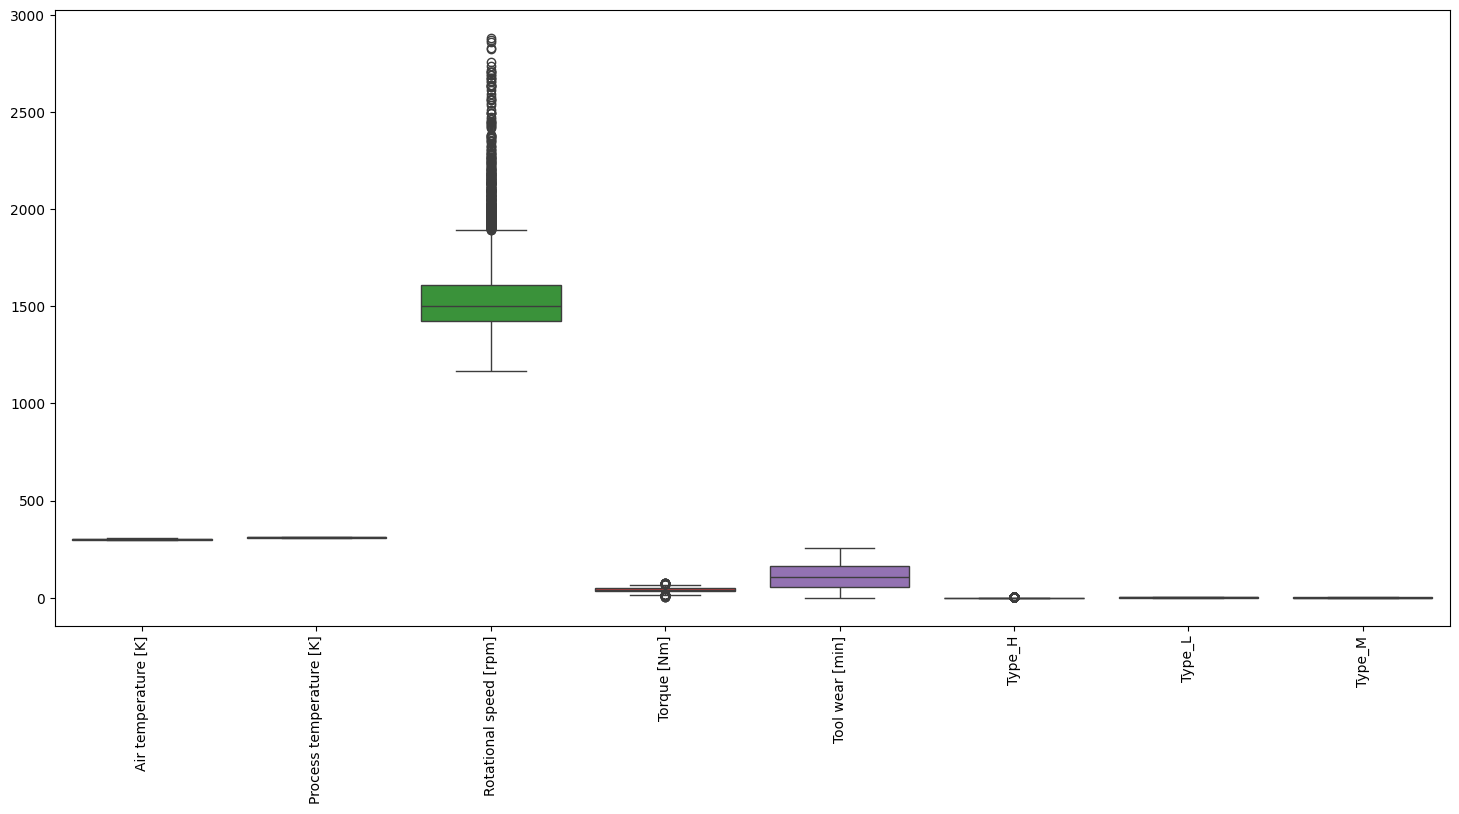

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
plt.figure(figsize=(18,8))
sns.boxplot(data=df.drop(columns=["Machine failure"]))
plt.xticks(rotation=90)
plt.show()

array([[<Axes: title={'center': 'Air temperature [K]'}>,
        <Axes: title={'center': 'Process temperature [K]'}>,
        <Axes: title={'center': 'Rotational speed [rpm]'}>],
       [<Axes: title={'center': 'Torque [Nm]'}>,
        <Axes: title={'center': 'Tool wear [min]'}>,
        <Axes: title={'center': 'Type_H'}>],
       [<Axes: title={'center': 'Type_L'}>,
        <Axes: title={'center': 'Type_M'}>, <Axes: >]], dtype=object)

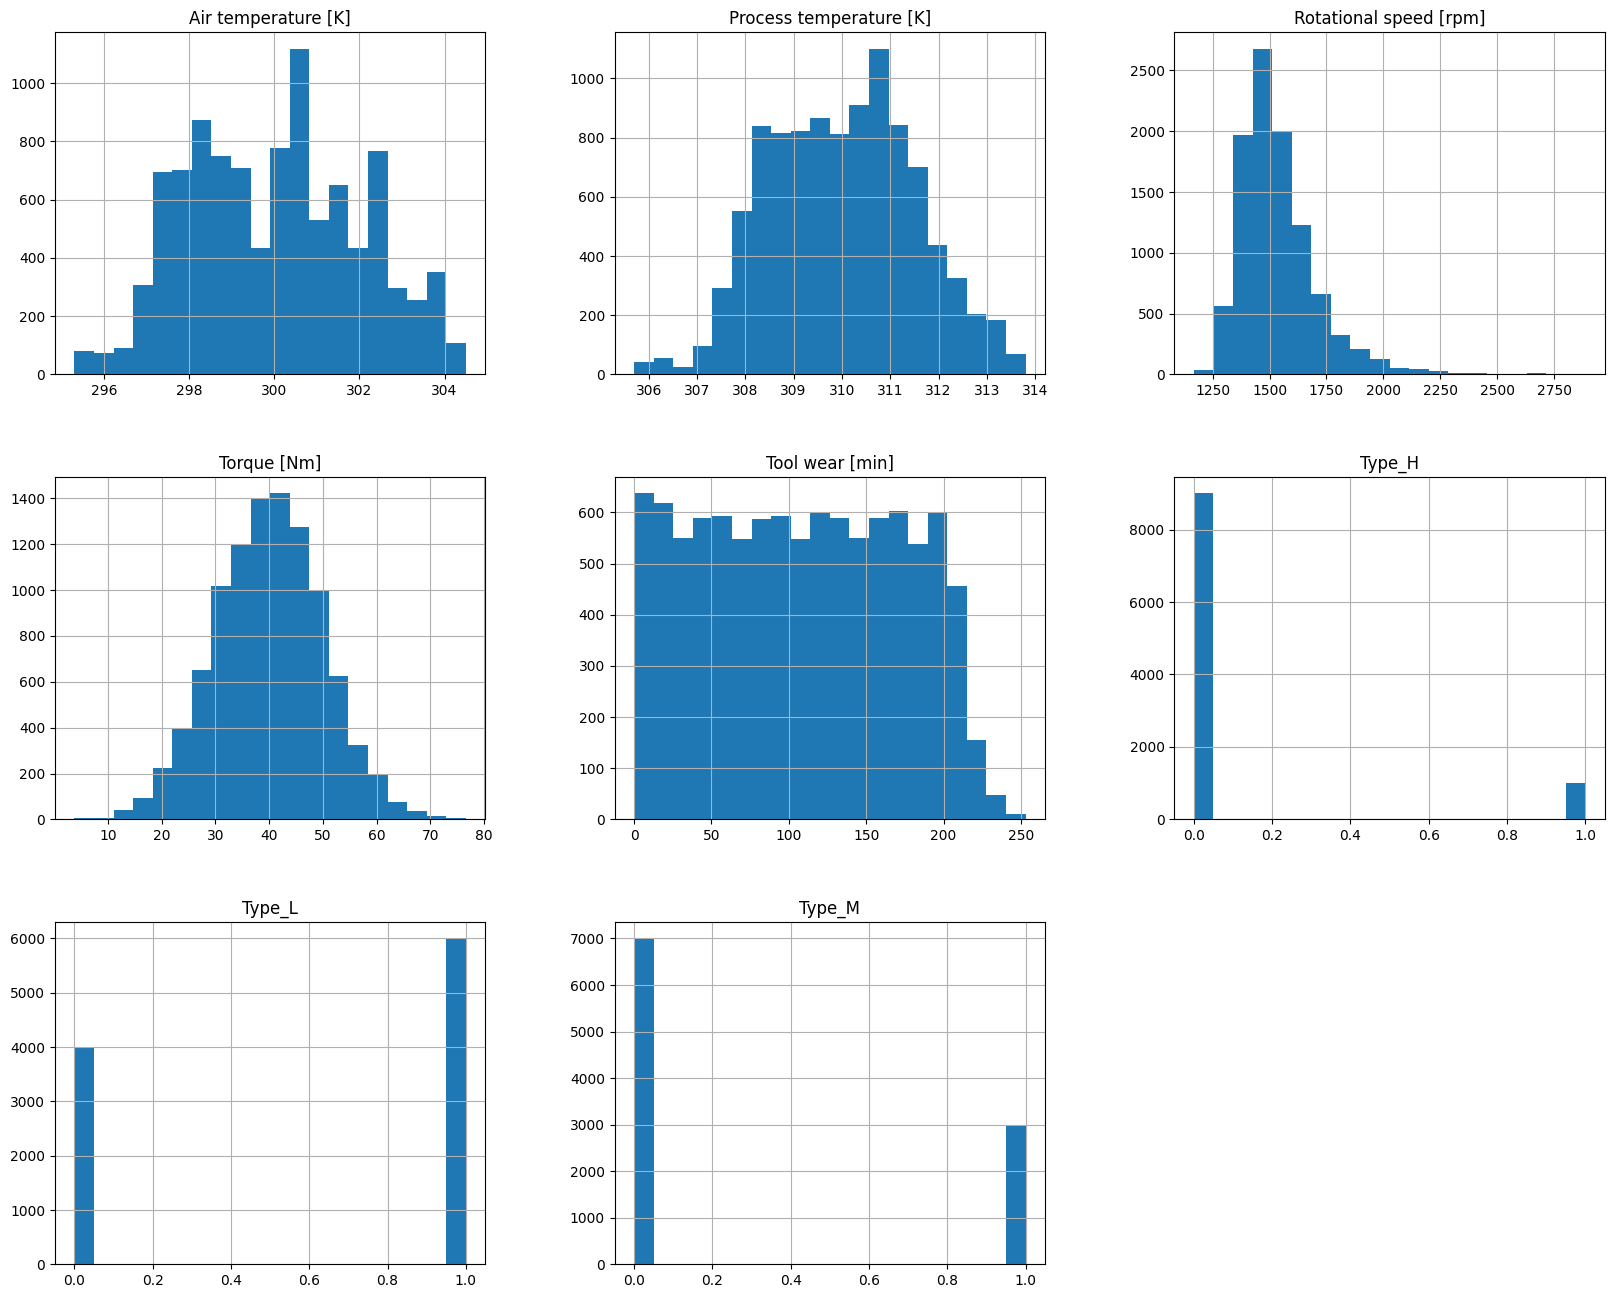

In [ ]:
df.drop(columns=["Machine failure"]).hist(figsize=(20,16),bins=20)

<Axes: >

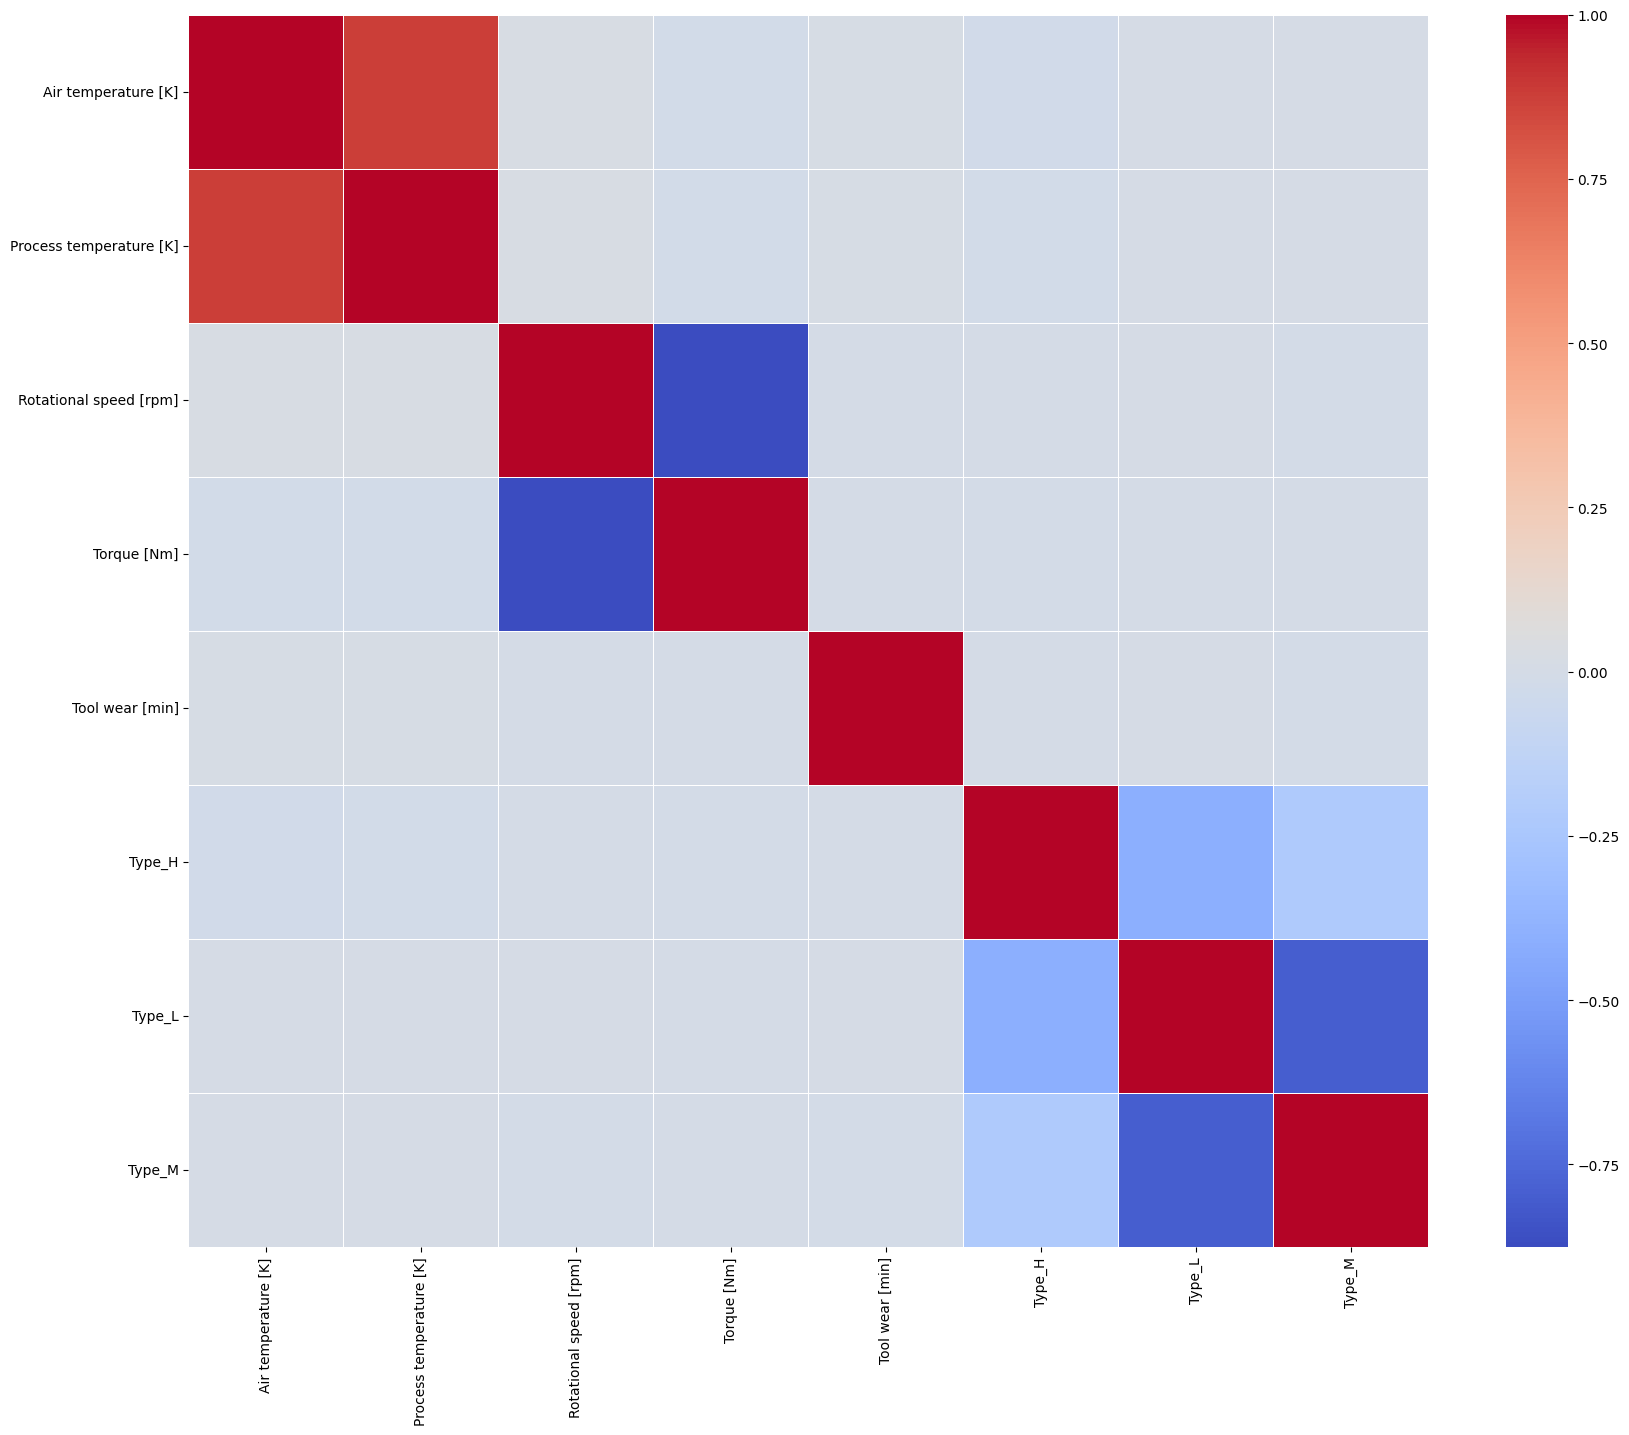

In [ ]:
correlation = df.drop(columns=["Machine failure"]).corr()
plt.figure(figsize=(20,16))
sns.heatmap(correlation,cmap="coolwarm",annot=False,linewidths=0.5)

In [ ]:
X = df.drop(columns=["Machine failure"])
y = df["Machine failure"]

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV,StratifiedKFold
from sklearn.metrics import accuracy_score,classification_report

In [ ]:
X_train,X_temp,y_train,y_temp = train_test_split(X,y,test_size=0.3,random_state=42,stratify=y)

In [ ]:
X_val,X_test,y_val,y_test = train_test_split(X_temp,y_temp,test_size=0.5,random_state=42,stratify=y_temp)

In [ ]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

In [ ]:
model = LogisticRegression(max_iter=1000,class_weight="balanced")
model.fit(X_train_scaled,y_train)
print("Model successsfully trained using LogisticRegression")

Model successsfully trained using LogisticRegression


In [ ]:
y_val_pred = model.predict(X_val_scaled)
y_test_pred = model.predict(X_test_scaled)

In [ ]:
accuracy_1 = accuracy_score(y_val,y_val_pred)
accuracy_2 = accuracy_score(y_test,y_test_pred)
print("Val Accuracy:",accuracy_1*100)
print("Test Accuracy:",accuracy_2*100)


Val Accuracy: 83.46666666666667
Test Accuracy: 82.8


In [ ]:
classification_report_1 = classification_report(y_val,y_val_pred)
classification_report_2 = classification_report(y_test,y_test_pred)
print("Val Classification Report:",classification_report_1)
print("Test classification Report:",classification_report_2)

Val Classification Report:               precision    recall  f1-score   support

           0       0.99      0.84      0.91      1449
           1       0.14      0.73      0.23        51

    accuracy                           0.83      1500
   macro avg       0.56      0.78      0.57      1500
weighted avg       0.96      0.83      0.88      1500

Test classification Report:               precision    recall  f1-score   support

           0       0.99      0.83      0.90      1449
           1       0.15      0.86      0.25        51

    accuracy                           0.83      1500
   macro avg       0.57      0.84      0.58      1500
weighted avg       0.97      0.83      0.88      1500



In [ ]:
model = RandomForestClassifier(random_state=42)
parameters = {
    "n_estimators": [100,200,300,400],
    "max_depth":[5,10,15,20],
    "min_samples_split":[2,5,7],
    "min_samples_leaf":[1,2,4]
}

In [ ]:
cv = StratifiedKFold(n_splits=5,shuffle=True,random_state=42)
grid_search_model = GridSearchCV(estimator=model,param_grid=parameters,cv=cv,scoring="accuracy",n_jobs=-1,verbose=1)


In [ ]:
grid_search_model.fit(X_train,y_train)
best_model = grid_search_model.best_estimator_
best_scoring = grid_search_model.best_score_
print("Best Model:",best_model)
print("Best CV Accuracy:",best_scoring)
y_val_pred_l = best_model.predict(X_val)
y_test_pred_l = best_model.predict(X_test)


Fitting 5 folds for each of 144 candidates, totalling 720 fits
Best Model: RandomForestClassifier(max_depth=15, n_estimators=200, random_state=42)
Best CV Accuracy: 0.9804285714285715


In [ ]:
accuracy_3 = accuracy_score(y_val,y_val_pred_l)
accuracy_4 = accuracy_score(y_test,y_test_pred_l)
print("Val Accuracy:",accuracy_3*100)
print("Test Accuracy:",accuracy_4*100)


Val Accuracy: 97.93333333333332
Test Accuracy: 97.8


In [ ]:
from sklearn.metrics import classification_report, confusion_matrix
print("Validation Classification Report:")
print(classification_report(y_val, y_val_pred_l))

print("Validation Confusion Matrix:")
print(confusion_matrix(y_val, y_val_pred_l))

Validation Classification Report:
              precision    recall  f1-score   support

           0       0.98      1.00      0.99      1449
           1       0.83      0.49      0.62        51

    accuracy                           0.98      1500
   macro avg       0.91      0.74      0.80      1500
weighted avg       0.98      0.98      0.98      1500

Validation Confusion Matrix:
[[1444    5]
 [  26   25]]


In [ ]:
print("Test Classification Report:")
print(classification_report(y_test, y_test_pred_l))

print("Test Confusion Matrix:")
print(confusion_matrix(y_test, y_test_pred_l))

Test Classification Report:
              precision    recall  f1-score   support

           0       0.98      1.00      0.99      1449
           1       0.85      0.43      0.57        51

    accuracy                           0.98      1500
   macro avg       0.91      0.71      0.78      1500
weighted avg       0.98      0.98      0.97      1500

Test Confusion Matrix:
[[1445    4]
 [  29   22]]


In [ ]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score
)

# Step 1: Get failure probabilities from Random Forest
y_val_prob_model = best_model.predict_proba(X_val)[:, 1]

# Step 2: Define thresholds to test
thresholds = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]

# Step 3: Test each threshold
for threshold in thresholds:

    # Convert probabilities into predictions
    y_val_pred_l_threshold = (
        y_val_prob_model >= threshold
    ).astype(int)

    print(f"\nThreshold: {threshold}")

    print("Accuracy:",
          accuracy_score(y_val, y_val_pred_l_threshold))

    print("\nClassification Report:")
    print(classification_report(
        y_val,
        y_val_pred_l_threshold,
        zero_division=0
    ))

    print("Confusion Matrix:")
    print(confusion_matrix(
        y_val,
        y_val_pred_l_threshold
    ))


Threshold: 0.1
Accuracy: 0.9486666666666667

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.95      0.97      1449
           1       0.39      0.90      0.54        51

    accuracy                           0.95      1500
   macro avg       0.69      0.93      0.76      1500
weighted avg       0.98      0.95      0.96      1500

Confusion Matrix:
[[1377   72]
 [   5   46]]

Threshold: 0.2
Accuracy: 0.9726666666666667

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.98      0.99      1449
           1       0.57      0.78      0.66        51

    accuracy                           0.97      1500
   macro avg       0.78      0.88      0.82      1500
weighted avg       0.98      0.97      0.97      1500

Confusion Matrix:
[[1419   30]
 [  11   40]]

Threshold: 0.3
Accuracy: 0.9786666666666667

Classification Report:
              precision    recall  f1-score   sup

In [ ]:
!pip install xgboost

In [ ]:
from xgboost import XGBClassifier

# Create the model
xgb_model = XGBClassifier(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=5,
    subsample=0.8,
    colsample_bytree=0.8,
    objective='binary:logistic',
    eval_metric='logloss',
    random_state=42,
    n_jobs=-1
)
X_train_xgb = X_train.copy()
X_val_xgb = X_val.copy()
X_test_xgb = X_test.copy()
X_train_xgb.columns = (
    X_train_xgb.columns
    .str.replace('[', '', regex=False)
    .str.replace(']', '', regex=False)
    .str.replace('<', '', regex=False)
)

X_val_xgb.columns = X_train_xgb.columns
X_test_xgb.columns = X_train_xgb.columns
print(X_train_xgb.columns.tolist())


['Air temperature K', 'Process temperature K', 'Rotational speed rpm', 'Torque Nm', 'Tool wear min', 'Type_H', 'Type_L', 'Type_M']


In [ ]:
# Train the model using the cleaned training features
xgb_model.fit(X_train_xgb, y_train)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=0.8, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.05, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=5, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=300, n_jobs=-1,
              num_parallel_tree=None, ...)

In [ ]:
y_val_pred_xgb = xgb_model.predict(X_val_xgb)
y_test_pred_xgb = xgb_model.predict(X_test_xgb)
print("Val accuracy:", accuracy_score(y_val, y_val_pred_xgb) * 100)
print("Test accuracy:", accuracy_score(y_test, y_test_pred_xgb) * 100)

Val accuracy: 98.26666666666667
Test accuracy: 98.33333333333333


In [ ]:
print("Val classification report:",classification_report(y_val,y_val_pred_xgb))
print("Test classification report:",classification_report(y_test,y_test_pred_xgb))

Val classification report:               precision    recall  f1-score   support

           0       0.99      1.00      0.99      1449
           1       0.82      0.63      0.71        51

    accuracy                           0.98      1500
   macro avg       0.90      0.81      0.85      1500
weighted avg       0.98      0.98      0.98      1500

Test classification report:               precision    recall  f1-score   support

           0       0.99      1.00      0.99      1449
           1       0.88      0.59      0.71        51

    accuracy                           0.98      1500
   macro avg       0.93      0.79      0.85      1500
weighted avg       0.98      0.98      0.98      1500

